In [1]:
# Konfiguracja wyglądu punktów i linii dopasowania
POINT_STYLE = {
    "stations": {"color": "#80C4E9", "size": 30, "alpha": 0.40, "linewidth": 0},
    "binned": {"color": "#102A43", "size": 70, "alpha": 0.7, "marker": "D"},
    "excluded": {"facecolor": "white", "edgecolor": "#102A43", "size": 70, "alpha": 0.7, "marker": "D", "linewidth": 2},
    "fit": "#8054A3",
}

from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

for path in [Path.cwd(), *Path.cwd().parents]:
    if (path / "log_binning_aw.py").is_file():
        if str(path) not in sys.path:
            sys.path.insert(0, str(path))
        break
else:
    raise FileNotFoundError("Could not find log_binning_aw.py")

from log_binning_aw import log_binning_aw

def _apply_project_plot_style():
    current = Path.cwd()
    for path in [current, *current.parents]:
        if (path / "plot_style.py").is_file():
            if str(path) not in sys.path:
                sys.path.insert(0, str(path))

            import plot_style

            plot_style.apply_montserrat_style()
            return

_apply_project_plot_style()


In [2]:
def find_project_root(start=None):
    current = Path.cwd() if start is None else Path(start)
    for path in [current, *current.parents]:
        if (path / "Data").exists():
            return path
    raise FileNotFoundError("Could not find project root containing Data/")


PROJECT_ROOT = find_project_root()
BASE_DIR = PROJECT_ROOT
DATA_DIR = PROJECT_ROOT / "Data"
DATA_FILE = DATA_DIR / "rides_data_without_discontinuities.parquet"

rides_data = pd.read_parquet(DATA_FILE, columns=[
    "start_station_id", "start_station_name", "start_date", "start_day_of_week"
])

### Wykluczanie stacji, dla których nie było ciągłości działania

In [3]:
# Stacje wykluczone z analizy
excluded_stations = {22181, 200032, 300060, 300074, 300099}

# Filtrowanie danych
rides_data_filtered = rides_data[
    ~pd.to_numeric(
        rides_data["start_station_id"], errors="coerce"
    ).isin(excluded_stations)
].copy()

# Podsumowanie
print(f"Liczba stacji przed filtrowaniem: {rides_data['start_station_id'].nunique()}")
print(f"Liczba stacji po filtrowaniu: {rides_data_filtered['start_station_id'].nunique()}")

Liczba stacji przed filtrowaniem: 801
Liczba stacji po filtrowaniu: 796


In [4]:
# Dane z pełnego zakresu lat 2024–2025, bez podziału na dni tygodnia
rides_data_all_days = rides_data_filtered.copy()

rides_data_all_days.head(5)


,start_station_id,start_station_name,start_date,start_day_of_week
0,200254,"Teviot Street, Poplar",2024-01-11 07:48:00,Thursday
1,300048,"Stainsby Road , Poplar",2024-01-11 08:25:00,Thursday
2,300208,"Lavington Street, Bankside",2024-01-11 15:07:00,Thursday
3,200105,"Bonny Street, Camden Town",2024-01-12 10:42:00,Friday
4,1194,"Westminster University, Marylebone",2024-01-13 11:36:00,Saturday


In [5]:
# Zamiana kolumny "start_date" na typ daty bez czasu
rides_data_all_days["start_date"] = rides_data_all_days["start_date"].dt.date


In [6]:
# Policzenie liczby przejazdów dla każdej stacji dzień po dniu
all_days_rides_per_station = (
    rides_data_all_days
    .groupby(["start_station_id", "start_date"])
    .size()
    .unstack()
)


In [7]:
# Wszystkie dni kalendarzowe w latach 2024–2025
days = pd.date_range("2024-01-01", "2025-12-31", freq="D").date

# Wszystkie analizowane stacje
station_ids = rides_data_filtered["start_station_id"].unique()

# Uzupełnienie brakujących dni i stacji zerami
all_days_rides_per_station = all_days_rides_per_station.reindex(
    index=station_ids, columns=days
).fillna(0)


In [8]:
# Średnia i wariancja dla każdej stacji
all_days_mean_and_variance_counts = pd.DataFrame({
    "mean_count": all_days_rides_per_station.mean(axis=1),
    "variance": all_days_rides_per_station.var(axis=1, ddof=0)
}).reset_index()


Pozbywanie się danych odstającyh - bardzo małych wartości

In [9]:
# Minimalne wartości średniej i wariancji
MIN_MEAN = 0.1
MIN_VARIANCE = 0.1

# Funkcja filtrująca
def filter_low_values(data):
    mask = (
        (data["mean_count"] >= MIN_MEAN) &
        (data["variance"] >= MIN_VARIANCE)
    )
    return data.loc[mask].copy()


# Filtrowanie danych
all_days_filtered = filter_low_values(all_days_mean_and_variance_counts)


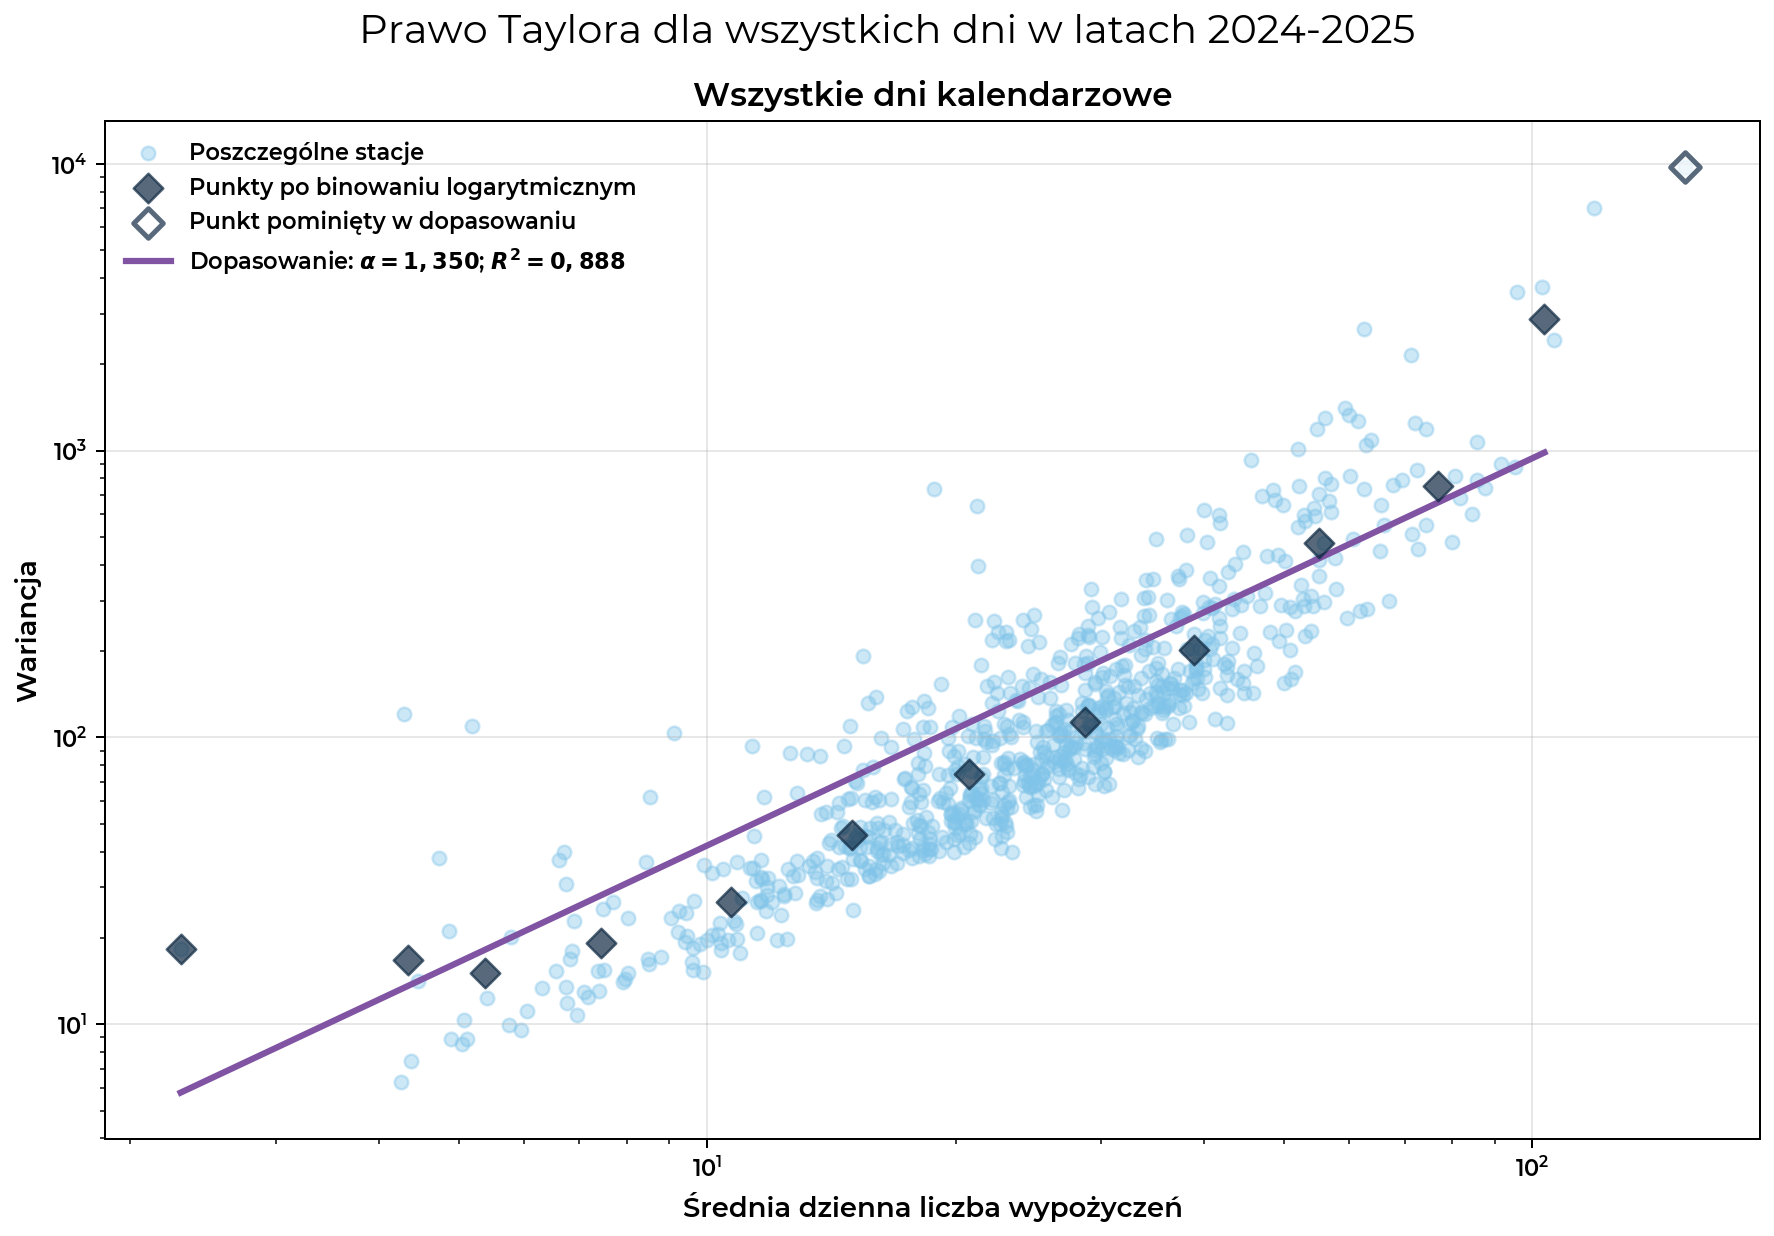

In [10]:
# Logarytmiczne przedziały
all_days_mean_log, all_days_variance_log = log_binning_aw(
    all_days_filtered["mean_count"],
    all_days_filtered["variance"],
    a=1.4
)

all_days_mean_log = np.asarray(all_days_mean_log)
all_days_variance_log = np.asarray(all_days_variance_log)

# Dopasowanie prawa Taylora z pominięciem ostatniego punktu
x = np.log(all_days_mean_log[:-1])
y = np.log(all_days_variance_log[:-1])

alpha, log_A = np.polyfit(x, y, 1)
A = np.exp(log_A)

# Ocena jakości dopasowania
y_pred = alpha * x + log_A
ss_res = np.sum((y - y_pred)**2)
ss_tot = np.sum((y - np.mean(y))**2)
r_squared = 1 - ss_res / ss_tot

r_squared_str = f"{r_squared:.3f}".replace(".", ",")
alpha_str = f"{alpha:.3f}".replace(".", ",")

# Generowanie punktów dopasowanej funkcji
x_fit = np.geomspace(min(all_days_mean_log[:-1]), max(all_days_mean_log[:-1]), 100)
y_fit = A * x_fit**alpha

# Wykres
_apply_project_plot_style()
fig, ax = plt.subplots(figsize=(10, 7))
styles = POINT_STYLE

# Chmura punktów – poszczególne stacje
ax.scatter(
    all_days_filtered["mean_count"],
    all_days_filtered["variance"],
    color=styles["stations"]["color"],
    alpha=styles["stations"]["alpha"],
    s=styles["stations"]["size"],
    zorder=1,
    label="Poszczególne stacje"
)

# Punkty po binowaniu uwzględnione w dopasowaniu
ax.scatter(
    all_days_mean_log[:-1],
    all_days_variance_log[:-1],
    color=styles["binned"]["color"],
    alpha=styles["binned"]["alpha"],
    marker=styles["binned"]["marker"],
    s=styles["binned"]["size"],
    zorder=3,
    label="Punkty po binowaniu logarytmicznym"
)

# Ostatni punkt pominięty w dopasowaniu
ax.scatter(
    all_days_mean_log[-1],
    all_days_variance_log[-1],
    marker=styles["excluded"]["marker"],
    facecolors=styles["excluded"]["facecolor"],
    edgecolors=styles["excluded"]["edgecolor"],
    alpha=styles["excluded"]["alpha"],
    linewidths=styles["excluded"]["linewidth"],
    s=styles["excluded"]["size"],
    zorder=3,
    label="Punkt pominięty w dopasowaniu"
)

# Dopasowana funkcja potęgowa
ax.plot(
    x_fit,
    y_fit,
    color=styles["fit"],
    linewidth=2.5,
    zorder=2,
    label=fr"Dopasowanie: $\alpha = {alpha_str}$; $R^2 = {r_squared_str}$"
)

# Skale i opisy wykresu
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("Średnia dzienna liczba wypożyczeń")
ax.set_ylabel("Wariancja")
ax.set_title("Wszystkie dni kalendarzowe")
ax.grid(alpha=0.3)
ax.legend(frameon=False)

fit_results = [{
    "period": "Wszystkie dni kalendarzowe",
    "alpha": alpha,
    "A": A,
    "r_squared": r_squared,
}]

fig.suptitle(
    "Prawo Taylora dla wszystkich dni w latach 2024-2025",
    fontsize=16
)

plt.tight_layout()
plt.show()
